## LDA LaBraM performance comparison

In [1]:
import os
from os import mkdir
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from core.datasets import KFoldSplitter, ClassFinetuneDataset
from core import settings, plot_data_processing, plotting
from core import io
from sklearn.linear_model import LogisticRegression

from core.io_models import Trial

In [2]:
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir('..')

labram_model_name = "class_nomask_10_22"
run_model_train = False

labram_model_dir = settings.FINETUNE_OUTPUT_DIR / labram_model_name
labram_inference_dir = settings.INFERENCE_DIR / labram_model_name
k_folds = 6
target_mode = "classify"  # the splitters load the input epochs only

# the same trials, window and labels as the LaBraM run: its baseline folds from keys.json, and every fold's post-patching
# test trials from the postpatch_keys.json its inference saved
if run_model_train:
    splitter = KFoldSplitter(input_data=settings.FINETUNE_INPUT_EPOCHS_DIR, target_data_dir=None,
                             target_mode=target_mode, seed=settings.SEED, k_folds=k_folds,
                             no_press_threshold=settings.NO_PRESS_FROM_SUBJECT)

    folds = splitter.split_from_keys(io.load_training_split_keys(labram_model_dir, k_folds))

    postpatch_splitter = KFoldSplitter(input_data=settings.PATCH_INPUT_EPOCHS_DIR, target_data_dir=None,
                                       target_mode=target_mode, seed=settings.SEED, k_folds=k_folds,
                                       no_press_threshold=settings.NO_PRESS_FROM_SUBJECT)
    postpatch_fold_keys = io.load_training_split_keys(labram_inference_dir, k_folds, filename="postpatch_keys.json")

    # interpolated channels of every trial, recorded in metadata["allowed"] (the non-masked LaBraM run saw them as normal inputs)
    interpolations_baseline = io.load_interpolated_channels(settings.FINETUNE_DIR / "epochs_manifest.csv")
    interpolations_postpatch = io.load_interpolated_channels(settings.PATCH_DIR / "epochs_manifest.csv")
    class_window = {"epoch_window": settings.EPOCH_WINDOW, "patch_window": settings.CLASS_PATCH_WINDOW, "fs": settings.RSFREQ,
                    "condition_classes": settings.CONDITION_CLASS_IDS}

    output_dir = settings.INFERENCE_DIR / "logistic_regression"
    c_rows = []  # train and val balanced accuracy of every fold and C, saved to c_sweep.csv
    for i, fold in enumerate(folds):

        train, val, test = fold.initialize_class_datasets(**class_window, interpolations=interpolations_baseline)
        postpatch_dataset = ClassFinetuneDataset(epochs_dict=postpatch_splitter.select(postpatch_fold_keys[i]["test"]),
                                                 **class_window, interpolations=interpolations_postpatch)

        X, y, meta = train.get_stacked_items()
        X_val, y_val, meta_val = val.get_stacked_items()
        X_test, y_test, meta_test = test.get_stacked_items()
        X_postpatch, y_postpatch, meta_postpatch = postpatch_dataset.get_stacked_items()

        # choose C based on validation
        best_score, best_model = 0, None
        for c in np.logspace(-5, 1, num=6):
            model = make_pipeline(StandardScaler(), LogisticRegression(penalty="l2", solver="lbfgs", C=c, max_iter=2000, random_state=settings.SEED))
            model.fit(X, y)
            bal_acc = balanced_accuracy_score(y_val, model.predict(X_val))
            train_bal_acc = balanced_accuracy_score(y, model.predict(X))
            c_rows.append({"fold": i + 1, "C": c, "train_balanced_accuracy": train_bal_acc, "val_balanced_accuracy": bal_acc})
            if bal_acc > best_score:
                best_score = bal_acc
                best_model = model
            print(f"Fold {i + 1}, C={c:.4f}: train balanced accuracy={train_bal_acc:.4f}, val={bal_acc:.4f}, best val={best_score:.4f}")

        test_logits = best_model.decision_function(X_test) # n trials x 8 (logits)
        postpatch_logits = best_model.decision_function(X_postpatch)

        print(f"Fold {i + 1}: test balanced accuracy {balanced_accuracy_score(y_test, test_logits.argmax(axis=1)):.4f}")

        # one file per session in the layout of run_inference.py: per trial the class id, the class logits as one row (1, n_classes),
        # so the mean over the first axis gives the class logits as for LaBraM's per-channel output, and the interpolated channels
        fold_dir = output_dir / str(i + 1)
        fold_dir.mkdir(parents=True, exist_ok=True)
        for session, logits, labels, metas in [("baseline", test_logits, y_test, meta_test), ("postpatch", postpatch_logits, y_postpatch, meta_postpatch)]:
            with h5py.File(fold_dir / f"{session}_reconstruction.h5", "w") as h5file:
                for trial_logits, label, trial_meta in zip(logits, labels, metas):
                    subj, cond, idx = trial_meta["subject"], trial_meta["condition"], trial_meta["id"]
                    io.save_inference_trial_hdf(subj, cond, idx, h5file, int(label), trial_logits[None, :], window_metrics={}, patch=None)
                    h5file[f"{subj}/{cond}/{idx}"].attrs["interpolated"] = np.flatnonzero(~trial_meta["allowed"].numpy())
    pd.DataFrame(c_rows).to_csv(output_dir / "c_sweep.csv", index=False)

## Logistic regression: train vs validation accuracy over C
Balanced accuracy on the training and the validation trials for every C (weaker regularisation to the right), mean ± SEM
over the folds, from the `c_sweep.csv` the training cell saves. The gap is marked at the C with the best mean validation
accuracy. A linear model with 23 x 200 features reaches perfect training accuracy as well, while validation stays low.

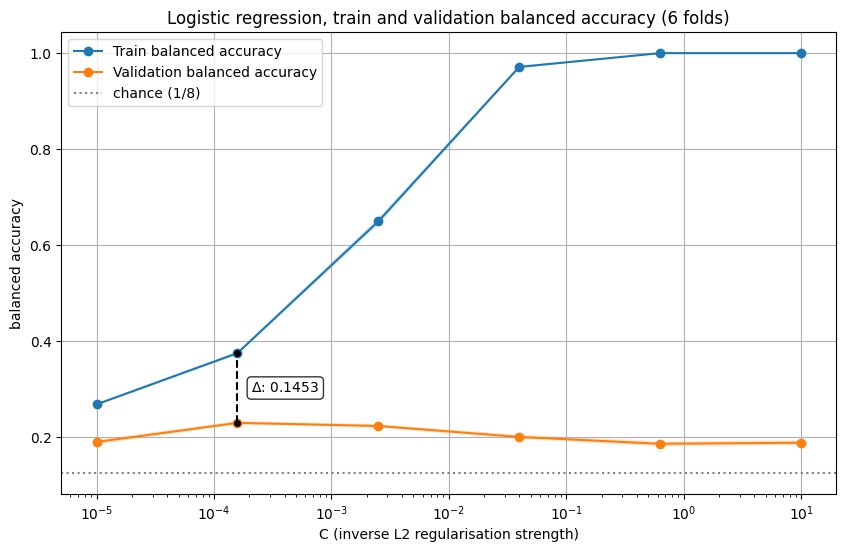

In [3]:
import matplotlib.pyplot as plt


c_sweep = pd.read_csv(settings.INFERENCE_DIR / "logistic_regression" / "c_sweep.csv")
curves = c_sweep.groupby("C")[["train_balanced_accuracy", "val_balanced_accuracy"]].agg(["mean", "sem"])
cs = curves.index.to_numpy()
fig, ax = plt.subplots(figsize=(10, 6))
for column, label in (("train_balanced_accuracy", "Train"), ("val_balanced_accuracy", "Validation")):
    mean, sem = curves[(column, "mean")].to_numpy(), curves[(column, "sem")].to_numpy()
    ax.plot(cs, mean, marker="o", label=f"{label} balanced accuracy")
    ax.fill_between(cs, mean - sem, mean + sem, alpha=0.2, linewidth=0)
ax.axhline(1 / settings.N_LOCATION_CLASSES, color="gray", linestyle=":", label="chance (1/8)")
best = curves[("val_balanced_accuracy", "mean")].to_numpy().argmax()
plotting.show_delta(ax, cs[best], curves[("train_balanced_accuracy", "mean")].iloc[best], curves[("val_balanced_accuracy", "mean")].iloc[best])
ax.set_xscale("log")
ax.set_xlabel("C (inverse L2 regularisation strength)")
ax.set_ylabel("balanced accuracy")
ax.set_title(f"Logistic regression, train and validation balanced accuracy ({c_sweep['fold'].nunique()} folds)")
ax.legend()
ax.grid()
plt.show()
plotting.save_button(fig, save_dir=settings.PLOT_DIR / "decoding", default_name=f"logreg_bal_acc")

In [4]:
from core import utils

# filters of the analysis, as in plasticity_plotting.ipynb. They select the trials loaded from the saved outputs only;
# the logistic regression above is trained on the same trials as LaBraM
subjects = None  # set to None to load all subjects
conditions = None  # set to None to load all location conditions; with a subset, the per-class AUCs of the missing classes can't be computed
id_low, id_high = None, None
trial_ids = [i for i in range(id_low, id_high)] if id_low is not None and id_high is not None else None  # set to None to load all trial ids
exclude_left_patched = True
exclude_right_patched_lefties = True  # set to True to exclude subjects with left eye dominance and right patching
exclude_button_press = False  # set to True to exclude button press trials (everything before STMD59)

# select subjects to exclude based on eye dominance, button press, and patching side
exclude_subjects = list(settings.EXCLUDED_SUBJECTS)
if exclude_left_patched:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT / "eye_dominance.csv"))
if exclude_right_patched_lefties:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT / "rightpatch_eye_dominance.csv"))  # after STMD35, all patches were on the right eye, so exclude lefties
if exclude_button_press:
    press_subjects = [subj for subj in io.get_stored_subject_names(settings.DATA_ROOT) if utils.subject_paradigm(subj, settings.NO_PRESS_FROM_SUBJECT) == "press"]
    exclude_subjects.extend(press_subjects)


In [5]:
# load the saved data
CH_NAMES = [name.replace("EEG ", "").replace("-REF", "") for name in settings.CHORDER_STANDARD]  # e.g. FP1, in the channel order of the outputs


def load_filtered_merged(model_name, mode="trial", ch_names=CH_NAMES, sessions=("baseline", "postpatch")):
    """
    The trial table (class_trials_frame) or, with mode="channel", the channel table (class_channels_frame) of the given
    sessions of a class run, all folds, with the filters above. A run trained on post-patching data has post-patching
    outputs only, sessions=("postpatch",).
    """
    frames = []
    for session in sessions:
        merged = []
        for i in range(1, 7):
            file_path = settings.INFERENCE_DIR / model_name / str(i) / f"{session}_reconstruction.h5"
            merged.extend(io.load_inference_trials(file_path, subjects=subjects, conditions=conditions, idxs=trial_ids, exclude_subjects=exclude_subjects, window="full", stim_patch=None))
        if mode == "channel":
            frames.append(plot_data_processing.class_channels_frame(merged, model_name, session=session, ch_names=ch_names))
        else:
            frames.append(plot_data_processing.class_trials_frame(merged, model_name, session=session))
    return pd.concat(frames, ignore_index=True)

logreg_df = load_filtered_merged("logistic_regression", )
labram_df = load_filtered_merged("class_nomask_10_22")
labram_df["model"] = "labram"

masked_channel_df = load_filtered_merged("class_10_22", mode="channel")  # the masked class run, with occlusion


compare_df = pd.concat([logreg_df, labram_df], ignore_index=True)

Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

In [6]:
def participant_scores(df: pd.DataFrame):
    proba = df[[f"p{k}" for k in range(8)]].to_numpy()
    auc = roc_auc_score(df["label"], proba, multi_class="ovr", average=None, labels=range(8))
    bal_acc = balanced_accuracy_score(df["label"], df["pred"])
    auc_format = {f"auc_{k}": a for k, a in enumerate(auc)}

    return pd.Series({"bal_acc": bal_acc, **auc_format, "n_trials": len(df)})


per_subj_scores = compare_df.groupby(["model", "session", "subject"]).apply(participant_scores).reset_index()

display(per_subj_scores.groupby(["model", "session"])["bal_acc"].agg(["mean", "sem", "count"]))

display(per_subj_scores.groupby(["model", "session"])[[f"auc_{k}" for k in range(8)]].agg(["mean"]))


mean       sem  count
model               session                             
labram              baseline   0.220997  0.006036     46
                    postpatch  0.214247  0.006915     46
logistic_regression baseline   0.234347  0.006379     46
                    postpatch  0.224304  0.007181     46

auc_0     auc_1     auc_2     auc_3  \
                                   mean      mean      mean      mean   
model               session                                             
labram              baseline   0.580583  0.639027  0.634145  0.599815   
                    postpatch  0.563971  0.640784  0.623749  0.590045   
logistic_regression baseline   0.595783  0.672482  0.682722  0.648420   
                    postpatch  0.593725  0.634005  0.651713  0.639675   

                                  auc_4     auc_5     auc_6     auc_7  
                                   mean      mean      mean      mean  
model               session                                            
labram              baseline   0.642552  0.624046  0.563276  0.601887  
                    postpatch  0.619868  0.628372  0.554177  0.596499  
logistic_regression baseline   0.665447  0.659258  0.580176  0.628508  
                    postpatch  0.657442  0.655832  0.581718  0.632662

In [7]:
per_subj_ch_masked = masked_channel_df.groupby(["session", "subject", "channel"])["occlusion_effect"].agg(["mean", "sem", "count"])

## Occlusion topomaps: change after patching
Masked LaBraM decoder (`class_10_22`): per channel, the drop of the true-class probability when the channel's cluster is
hidden, averaged per subject and session (interpolated channels left out), then over subjects. The change is post-patching
minus baseline per subject, shown as mean change and as d_z.
- **absolute**: the drop itself. The decoder was trained on baseline only, so post-patching trials are decoded less
  confidently overall, which makes every drop smaller: the absolute change mixes that with region-specific changes.
- **relative**: the drop as a share of the trial's true-class probability without hiding, which removes the overall
  confidence difference and shows whether the spatial pattern changed.

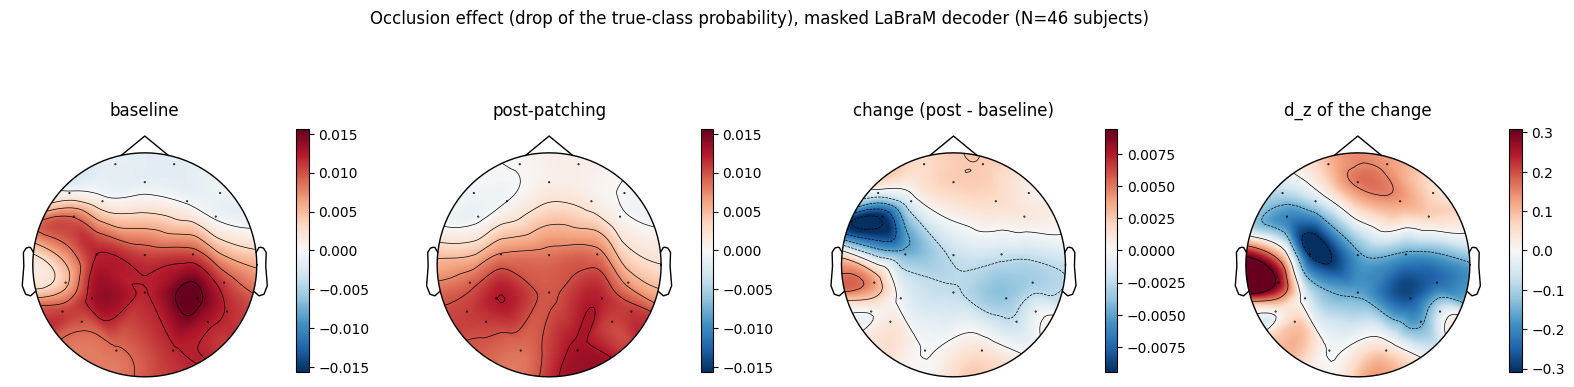

Occlusion effect (drop of the true-class probability), change (post - baseline):
  max: T3 +0.0038, FP2 +0.0024, FZ +0.0023
  min: F7 -0.0094, C3 -0.0043, P4 -0.0037


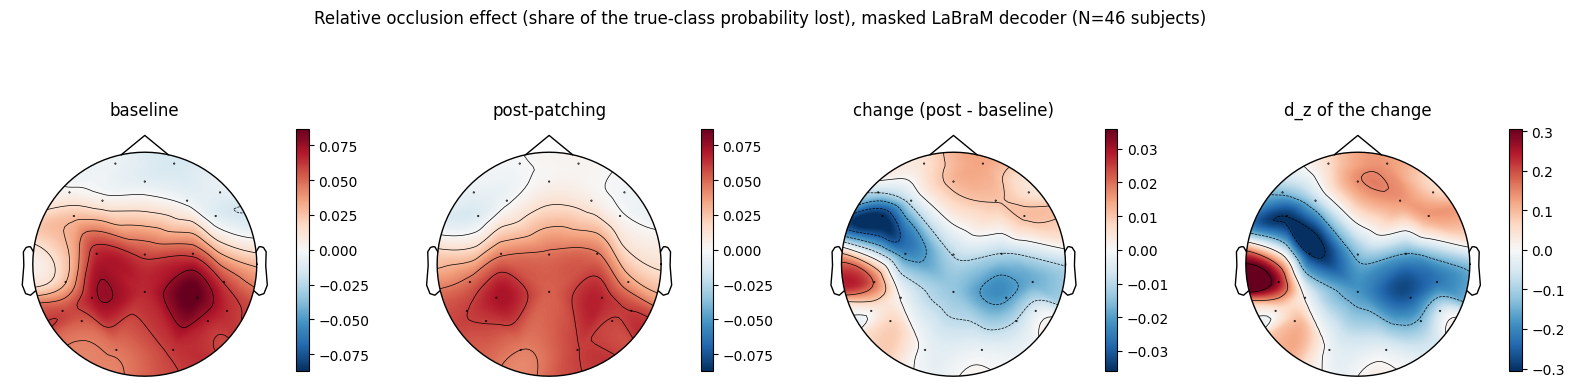

Relative occlusion effect (share of the true-class probability lost), change (post - baseline):
  max: T3 +0.0193, FP2 +0.0140, FZ +0.0118
  min: F7 -0.0359, C3 -0.0233, P4 -0.0211


In [8]:
import matplotlib.pyplot as plt
import mne

topo_info = plot_data_processing.create_topomap_info()  # 10-20 labels at the HydroCel positions, in CH_NAMES order
# true-class probability without hiding = occlusion_effect + occluded_p_true
masked_channel_df["p_true"] = masked_channel_df["occlusion_effect"] + masked_channel_df["occluded_p_true"]


def channel_change_topomaps(df, label, value="occlusion_effect", relative=False, model_label="masked LaBraM decoder"):
    """
    Topomaps of a per-channel column of a channel table (class_channels_frame): the subject means per session (baseline
    and post-patching on one colour scale), the mean change (post-patching - baseline) and its d_z over the subjects with
    both sessions. NaN (interpolated) rows are left out of the subject means. Prints the 3 channels with the largest and
    the 3 with the smallest change.
    relative (occlusion only): the subject's mean drop divided by its mean true-class probability without hiding, per
    session and channel (a ratio of means: per-trial ratios explode for trials with a true-class probability near 0).
    """
    grouped = df.groupby(["session", "subject", "channel"])
    subject_means = grouped[value].mean()
    if relative:
        subject_means = subject_means / grouped["p_true"].mean()  # p_true is NaN on the same (interpolated) rows
    subject_means = subject_means.unstack("channel")[CH_NAMES]
    baseline, postpatch = subject_means.loc["baseline"], subject_means.loc["postpatch"]
    subjects = baseline.index.intersection(postpatch.index)
    change = postpatch.loc[subjects] - baseline.loc[subjects]
    maps = {"baseline": baseline.loc[subjects].mean(), "post-patching": postpatch.loc[subjects].mean(),
            "change (post - baseline)": change.mean(), "d_z of the change": change.mean() / change.std(ddof=1)}
    # the session maps share one scale: symmetric around 0 if the values can be negative, from min to max otherwise
    session_values = pd.concat([maps["baseline"], maps["post-patching"]])
    if session_values.min() < 0:
        session_vlim, session_cmap = (-session_values.abs().max(), session_values.abs().max()), "RdBu_r"
    else:
        session_vlim, session_cmap = (session_values.min(), session_values.max()), "viridis"

    fig, axes = plt.subplots(1, len(maps), figsize=(5 * len(maps), 4.5))
    for ax, (title, values) in zip(axes, maps.items()):
        session_map = title in ("baseline", "post-patching")
        vlim = session_vlim if session_map else (-values.abs().max(), values.abs().max())
        values = values.to_numpy(dtype=float)
        keep = np.flatnonzero(np.isfinite(values))
        im, _ = mne.viz.plot_topomap(values[keep], mne.pick_info(topo_info, keep), axes=ax, show=False, vlim=vlim,
                                     cmap=session_cmap if session_map else "RdBu_r")
        ax.set_title(title)
        fig.colorbar(im, ax=ax, shrink=0.7)
    fig.suptitle(f"{label}, {model_label} (N={len(subjects)} subjects)", y=1.03)
    plt.show()

    ordered = maps["change (post - baseline)"].dropna().sort_values()
    print(f"{label}, change (post - baseline):")
    print("  max: " + ", ".join(f"{ch} {v:+.4f}" for ch, v in ordered[::-1][:3].items()))
    print("  min: " + ", ".join(f"{ch} {v:+.4f}" for ch, v in ordered[:3].items()))


channel_change_topomaps(masked_channel_df, "Occlusion effect (drop of the true-class probability)")
channel_change_topomaps(masked_channel_df, "Relative occlusion effect (share of the true-class probability lost)", relative=True)


## Occlusion with one model per session
The maps above score the post-patching trials with the model trained on the baseline, so their post-patching occlusion
mixes where the information is with how well the baseline model's rules still fit after patching. Here every session is
scored by a masked model trained on that session (`run_general_finetune.py --task_classify --masked --postpatch`, the same
settings as the baseline run, and `run_inference.py` on it): the change is the change of where the location information
is. Two separately trained models also differ by training noise, so part of the change is the models', not the brains'.

Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

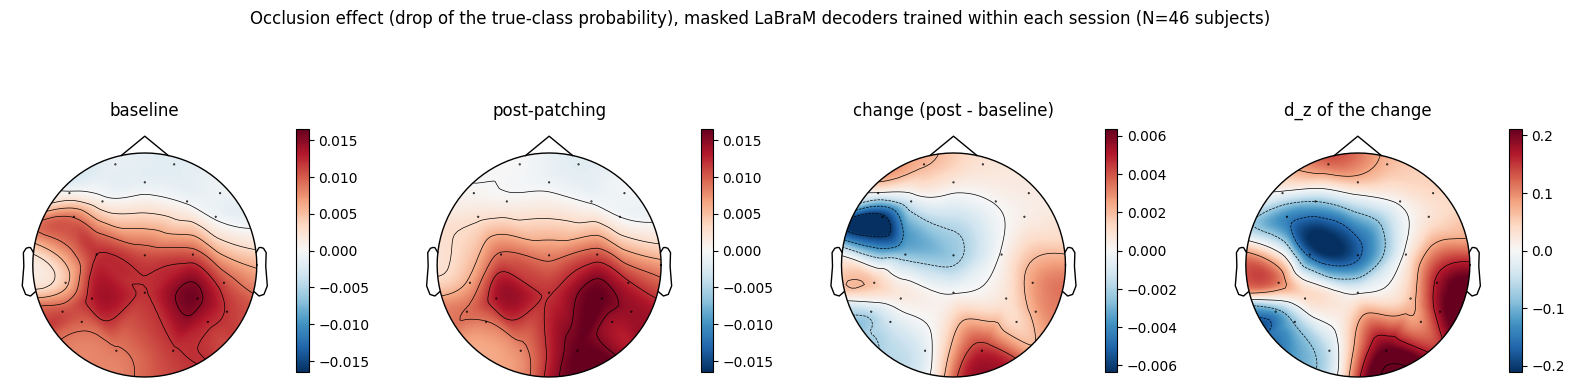

Occlusion effect (drop of the true-class probability), change (post - baseline):
  max: O2 +0.0046, T4 +0.0026, A2 +0.0024
  min: F7 -0.0063, C3 -0.0027, CZ -0.0024


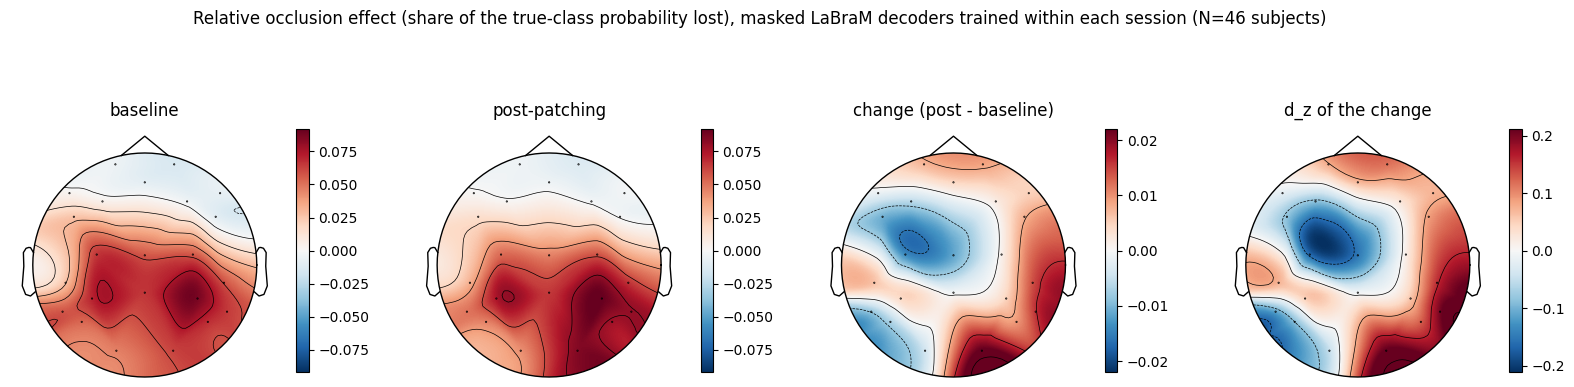

Relative occlusion effect (share of the true-class probability lost), change (post - baseline):
  max: O2 +0.0220, A2 +0.0157, T4 +0.0139
  min: C3 -0.0141, CZ -0.0114, F7 -0.0106


In [9]:
postpatch_masked_name = "class_postpatch_10_26"  # masked class run trained on post-patching data, same settings as class_10_22
within_channel_df = pd.concat([load_filtered_merged("class_10_22", mode="channel", sessions=("baseline",)),
                               load_filtered_merged(postpatch_masked_name, mode="channel", sessions=("postpatch",))], ignore_index=True)
within_channel_df["p_true"] = within_channel_df["occlusion_effect"] + within_channel_df["occluded_p_true"]
within_label = "masked LaBraM decoders trained within each session"
channel_change_topomaps(within_channel_df, "Occlusion effect (drop of the true-class probability)", model_label=within_label)
channel_change_topomaps(within_channel_df, "Relative occlusion effect (share of the true-class probability lost)", relative=True,
                        model_label=within_label)


## Time-resolved decoding (Task A)
Sliding shrinkage LDA (`python -m decoding.run_sliding_lda --keys_from class_nomask_10_22`): one pooled model per fold,
session, band and time point on LaBraM's folds, trained within each session, features standardized per subject. Every
trial's -0.5 to 0.5 s window is band-passed into `DECODING_BANDS` (broadband: low-pass 45 Hz, keeps the slow evoked
response) and decimated to 100 Hz. The metrics are computed per subject from its out-of-fold test trials: balanced
accuracy (chance 1/8) and one-vs-rest AUC per class (chance 0.5) at every time point. The filters above select the subjects
and trials; run the cells per cohort (`exclude_button_press`) as the handoff asks, without pooling the cohorts.
Bars under the curves: time clusters above chance (one-sided cluster permutation test over subjects, p < 0.05).

In [11]:
import h5py
import matplotlib.pyplot as plt
from core.decoding import metrics as decoding_metrics

sliding_name = "sliding_lda"  # output folder of decoding/run_sliding_lda.py
n_permutations = 5000


def load_time_metrics(name, file_suffix="reconstruction"):
    """
    Per-subject time metrics (decoding_metrics.time_metrics_frame) of both sessions of a sliding decoder, with the filters
    above, from its {session}_{file_suffix}.h5 files ("searchlight": the searchlight outputs, one set per channel).
    """
    run_dir = settings.INFERENCE_DIR / name
    folds = sorted(int(d.name) for d in run_dir.iterdir() if d.is_dir() and d.name.isdigit())
    frames = []
    for session in ("baseline", "postpatch"):
        trials = []
        for k in folds:
            path = run_dir / str(k) / f"{session}_{file_suffix}.h5"
            with h5py.File(path, "r") as f:
                set_names, times = [str(s) for s in f.attrs["sets"]], np.asarray(f.attrs["times"])
            trials.extend(io.load_inference_trials(path, subjects=subjects, conditions=conditions, idxs=trial_ids,
                                                   exclude_subjects=exclude_subjects, stim_patch=None))
        frames.append(decoding_metrics.time_metrics_frame(trials, name, session, set_names, times, settings.N_LOCATION_CLASSES))
    return pd.concat(frames, ignore_index=True), set_names, times


time_df, set_names, times = load_time_metrics(sliding_name)
time_df.head()


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

,model,session,subject,n_trials,set,time,metric,class,value
0,sliding_lda,baseline,STMD1,158,broadband (0.1-45Hz),-0.50,balanced_accuracy,-1,0.171382
1,sliding_lda,baseline,STMD1,158,broadband (0.1-45Hz),-0.49,balanced_accuracy,-1,0.228618
2,sliding_lda,baseline,STMD1,158,broadband (0.1-45Hz),-0.48,balanced_accuracy,-1,0.177961
3,sliding_lda,baseline,STMD1,158,broadband (0.1-45Hz),-0.47,balanced_accuracy,-1,0.146382
4,sliding_lda,baseline,STMD1,158,broadband (0.1-45Hz),-0.46,balanced_accuracy,-1,0.145395


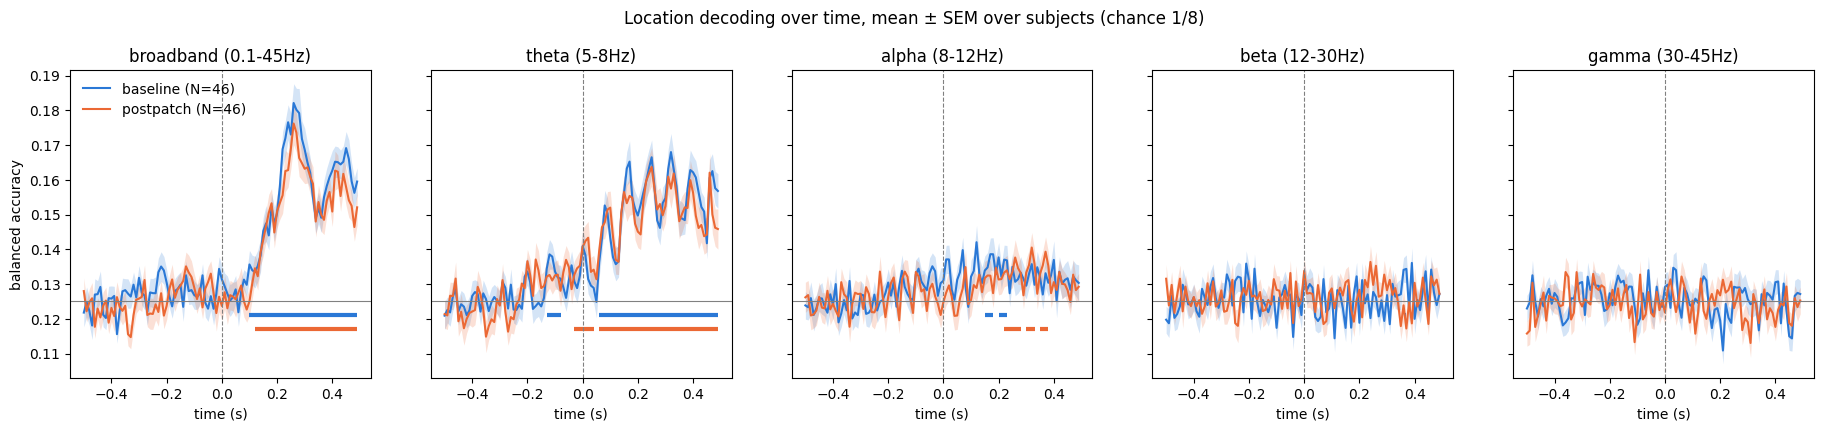

,set,session,start,end,p
0,broadband (0.1-45Hz),baseline,-0.30,-0.30,0.714
1,broadband (0.1-45Hz),baseline,-0.23,-0.21,0.135
2,broadband (0.1-45Hz),baseline,-0.13,-0.13,0.754
3,broadband (0.1-45Hz),baseline,-0.07,-0.07,0.556
4,broadband (0.1-45Hz),baseline,-0.01,-0.01,0.454
...,...,...,...,...,...
75,gamma (30-45Hz),postpatch,-0.36,-0.35,0.344
76,gamma (30-45Hz),postpatch,-0.32,-0.32,0.815
77,gamma (30-45Hz),postpatch,-0.26,-0.26,0.892
78,gamma (30-45Hz),postpatch,-0.09,-0.09,0.950


In [12]:
chance = 1 / settings.N_LOCATION_CLASSES
session_colors = {"baseline": "#2a78d6", "postpatch": "#eb6834"}
cluster_rows = []

fig, axes = plt.subplots(1, len(set_names), figsize=(4.5 * len(set_names), 4), sharey=True)
for ax, set_name in zip(axes, set_names):
    for offset, (session, color) in enumerate(session_colors.items()):
        curves = decoding_metrics.subject_curves(time_df, {"session": session, "set": set_name, "metric": "balanced_accuracy"})
        mean, err = curves.mean(), curves.sem()
        ax.plot(curves.columns, mean, color=color, label=f"{session} (N={len(curves)})")
        ax.fill_between(curves.columns, mean - err, mean + err, color=color, alpha=0.2, linewidth=0)
        for first, last, p in decoding_metrics.cluster_test_vs_chance(curves.to_numpy(), chance, n_permutations, settings.SEED):
            cluster_rows.append({"set": set_name, "session": session, "start": curves.columns[first], "end": curves.columns[last], "p": p})
            if p < 0.05:
                ax.hlines(chance - 0.004 * (offset + 1), curves.columns[first], curves.columns[last], color=color, linewidth=3)
    ax.axhline(chance, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(set_name)
    ax.set_xlabel("time (s)")
axes[0].set_ylabel("balanced accuracy")
axes[0].legend(frameon=False)
fig.suptitle("Location decoding over time, mean ± SEM over subjects (chance 1/8)", y=1.03)
plt.show()
display(pd.DataFrame(cluster_rows).round(3))


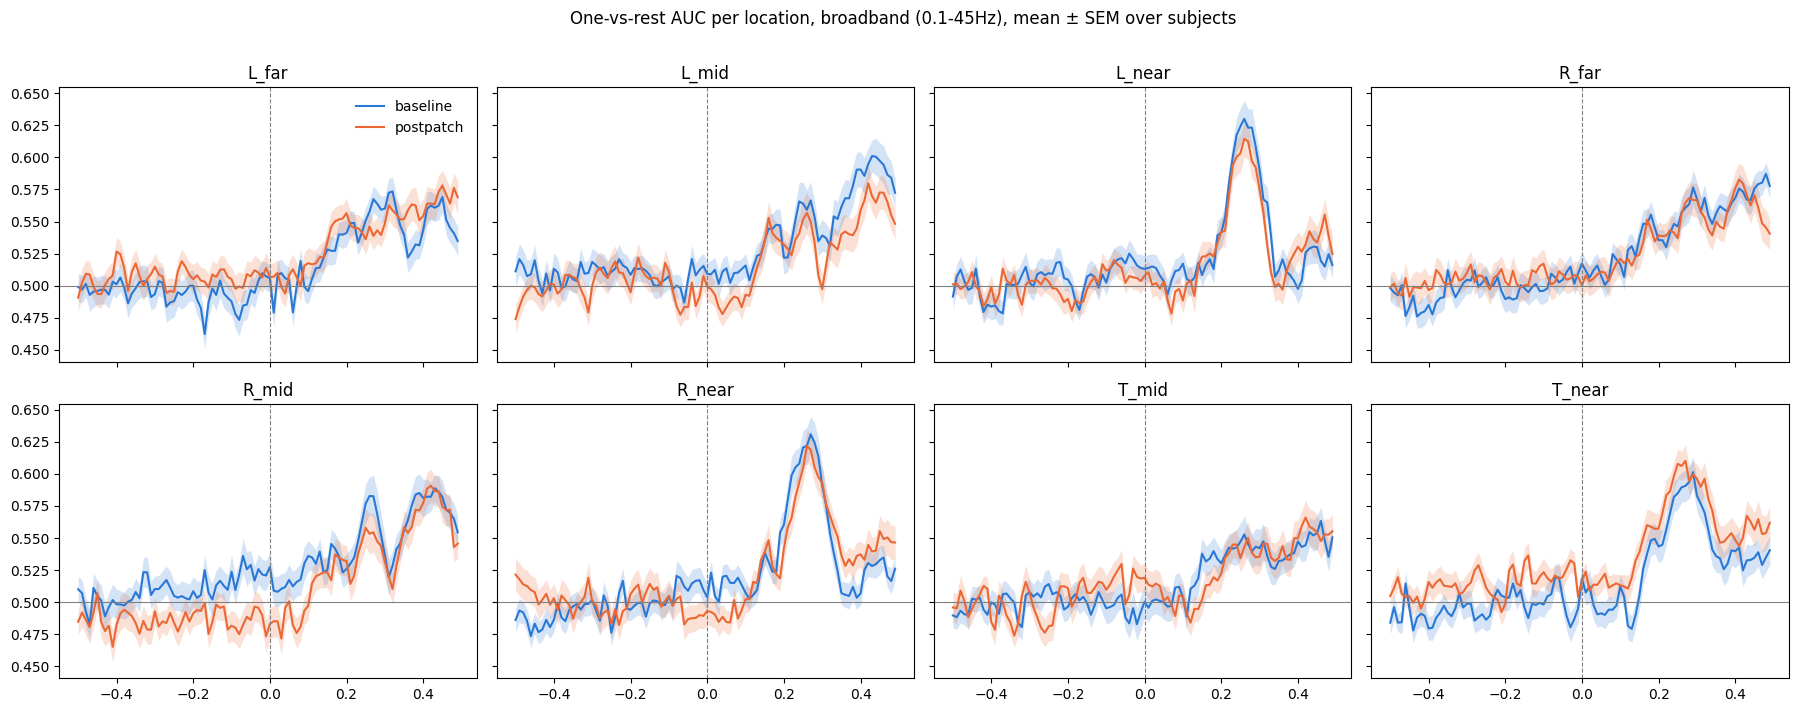

In [13]:
# one-vs-rest AUC per class over time, primary set (broadband), per session
primary_set = set_names[0]
class_labels = {info["class_id"]: info["label"] for info in settings.LOCATION_CLASSES.values()}
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True, sharey=True)
for class_id, ax in zip(range(settings.N_LOCATION_CLASSES), axes.flat):
    for session, color in session_colors.items():
        curves = decoding_metrics.subject_curves(time_df, {"session": session, "set": primary_set, "metric": "auc", "class": class_id})
        mean, err = curves.mean(), curves.sem()
        ax.plot(curves.columns, mean, color=color, label=session)
        ax.fill_between(curves.columns, mean - err, mean + err, color=color, alpha=0.2, linewidth=0)
    ax.axhline(0.5, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(class_labels[class_id])
axes[0, 0].legend(frameon=False)
fig.suptitle(f"One-vs-rest AUC per location, {primary_set}, mean ± SEM over subjects", y=1.01)
plt.tight_layout()
plt.show()


## Side contrasts: latency and accuracy (Task B)
Per-class AUC curves of the primary set (broadband), classes relabelled per subject relative to the patched eye:
"patched" = the side of the patched eye, "other" the other side, "top" the top wall (`decoding_metrics.side_slots`).
- **Accuracy**: mean AUC in `Q4_ACCURACY_WINDOW`, fixed once from the baseline grand average (B1) before the post data are
  looked at. While it is None, the cell below suggests the largest baseline cluster above chance: write it into settings.
- **Latency**: the AUC curves smoothed over `Q4_LATENCY_SMOOTHING`, then the first time in `Q4_LATENCY_SEARCH` where the
  curve reaches `Q4_PEAK_FRACTION` of its peak above 0.5 (B2), on the mean curves, tested with the jackknife (B3).
- **Contrasts** (B5): Δ = post-patching - baseline per class, then patched - other side (near, mid, far) and top - mean of
  the sides (near, mid). Holm correction over the 10 change tests (5 contrasts x 2 measures); the baseline-only contrasts are
  reported alongside with their own correction.

In [14]:
auc_df = time_df[(time_df["metric"] == "auc") & (time_df["set"] == primary_set)]

# B1: the accuracy window, from the baseline grand average over all classes only
if settings.Q4_ACCURACY_WINDOW is None:
    grand = auc_df[auc_df["session"] == "baseline"].groupby(["subject", "time"])["value"].mean().unstack("time")
    found = [c for c in decoding_metrics.cluster_test_vs_chance(grand.to_numpy(), 0.5, n_permutations, settings.SEED) if c[2] < 0.05]
    if not found:
        raise ValueError("No baseline cluster above chance, the accuracy window can't be chosen")
    first, last, p = max(found, key=lambda c: c[1] - c[0])
    accuracy_window = (round(float(grand.columns[first]), 3), round(float(grand.columns[last]), 3))
    print(f"Suggested Q4_ACCURACY_WINDOW = {accuracy_window} (baseline cluster p = {p:.4f}); write it into settings before looking at post data")
else:
    accuracy_window = settings.Q4_ACCURACY_WINDOW
print(f"Accuracy window: {accuracy_window} s")


Suggested Q4_ACCURACY_WINDOW = (0.08, 0.49) (baseline cluster p = 0.0002); write it into settings before looking at post data
Accuracy window: (0.08, 0.49) s


In [15]:
def q4_contrasts(time_df, accuracy_window, set_name):
    """
    The Task B contrast table of a time table (load_time_metrics): per-subject one-vs-rest AUC curves of set_name, the
    classes as side slots relative to the patched eye (subjects with both sessions and a known patched eye), accuracy =
    mean AUC in accuracy_window, latency = fractional peak latency of the smoothed mean curves (jackknife), Holm-corrected
    per kind. Returns (contrast table, Q4 subjects).
    """
    auc_df = time_df[(time_df["metric"] == "auc") & (time_df["set"] == set_name)]

    def class_curves(session):  # {subject: (n_classes, n_times)}
        table = auc_df[auc_df["session"] == session].pivot_table(index=["subject", "class"], columns="time", values="value")
        return {s: table.loc[s].reindex(range(settings.N_LOCATION_CLASSES)).to_numpy() for s in table.index.get_level_values(0).unique()}

    baseline_curves, postpatch_curves = class_curves("baseline"), class_curves("postpatch")
    both = sorted(set(baseline_curves) & set(postpatch_curves))
    baseline_slots, q4_subjects = decoding_metrics.side_slots(np.stack([baseline_curves[s] for s in both]), both, eyes, settings.LOCATION_CLASSES)
    postpatch_slots, _ = decoding_metrics.side_slots(np.stack([postpatch_curves[s] for s in both]), both, eyes, settings.LOCATION_CLASSES)
    curve_times = np.asarray(auc_df["time"].drop_duplicates().sort_values())

    # accuracy: mean AUC in the window; latency: smoothed curves, fractional peak latency on the mean curves (jackknife)
    in_window = (curve_times >= accuracy_window[0] - 1e-9) & (curve_times <= accuracy_window[1] + 1e-9)
    accuracy = decoding_metrics.accuracy_contrasts(baseline_slots[..., in_window].mean(-1), postpatch_slots[..., in_window].mean(-1))
    smoothing = round(settings.Q4_LATENCY_SMOOTHING / (curve_times[1] - curve_times[0]))
    latency = decoding_metrics.latency_contrasts(curve_times, decoding_metrics.smooth(baseline_slots, smoothing),
                                                 decoding_metrics.smooth(postpatch_slots, smoothing), 0.5,
                                                 settings.Q4_PEAK_FRACTION, settings.Q4_LATENCY_SEARCH)
    q4 = pd.concat([accuracy, latency], ignore_index=True)
    for kind in ("change", "baseline only"):
        q4.loc[q4["kind"] == kind, "p_holm"] = decoding_metrics.holm(q4.loc[q4["kind"] == kind, "p"])
    return q4, q4_subjects


eyes = decoding_metrics.patched_eyes(settings.DATA_ROOT / "eye_dominance.csv", settings.DATA_ROOT / "rightpatch_eye_dominance.csv")
q4, q4_subjects = q4_contrasts(time_df, accuracy_window, primary_set)
print(f"Q4 subjects with a known patched eye: {len(q4_subjects)}")
display(q4.round(4))


Q4 subjects with a known patched eye: 45


,contrast,measure,ecc,kind,estimate,se,t,df,p,p_wilcoxon,n,p_holm
0,patched - other,accuracy,near,change,0.0100,0.0094,1.0551,44,0.2972,0.3294,45,1.0000
1,patched - other,accuracy,near,baseline only,0.0042,0.0067,0.6329,44,0.5301,0.4737,45,1.0000
2,patched - other,accuracy,mid,change,0.0088,0.0134,0.6550,44,0.5159,0.7038,45,1.0000
3,patched - other,accuracy,mid,baseline only,-0.0023,0.0097,-0.2340,44,0.8161,0.9288,45,1.0000
4,patched - other,accuracy,far,change,-0.0140,0.0126,-1.1044,44,0.2754,0.2430,45,1.0000
5,patched - other,accuracy,far,baseline only,0.0122,0.0067,1.8104,44,0.0771,0.0654,45,0.7706
6,top - sides,accuracy,near,change,0.0160,0.0131,1.2176,44,0.2299,0.1924,45,1.0000
7,top - sides,accuracy,near,baseline only,0.0007,0.0102,0.0646,44,0.9487,1.0000,45,1.0000
8,top - sides,accuracy,mid,change,0.0088,0.0146,0.6042,44,0.5488,0.5607,45,1.0000
9,top - sides,accuracy,mid,baseline only,-0.0185,0.0107,-1.7344,44,0.0898,0.1173,45,0.8086


## Searchlight: where location is decodable, per band
The same sliding LDA, trained on every channel's cluster alone (the channel and its nearest electrodes,
`run_sliding_lda.py --searchlight`), in every band, so every channel gets its own decoding accuracy over time per band.
Mapped per band: the balanced accuracy above chance in the Task B accuracy window, per session, the change
(post-patching - baseline) and its d_z over the subjects with both sessions. Each band's maps have their own colour
scale. Neighbouring clusters share channels, so neighbouring values are not independent. The zero-phase filter smears
the narrow bands in time (theta most), so a band's map says where the band carries location information, not when.

In [16]:
from core.decoding.data import band_file_name

# window-averaged searchlight accuracy - chance per band: one row per session, subject and channel
searchlight_maps = {}
for band in settings.DECODING_BANDS:
    file_suffix = f"searchlight_{band_file_name(band)}"
    if not (settings.INFERENCE_DIR / sliding_name / "1" / f"baseline_{file_suffix}.h5").exists():
        print(f"No searchlight outputs for {band}, skipped")
        continue
    searchlight_df, cluster_names, _ = load_time_metrics(sliding_name, file_suffix=file_suffix)
    window_rows = searchlight_df[(searchlight_df["metric"] == "balanced_accuracy")
                                 & searchlight_df["time"].between(accuracy_window[0] - 1e-9, accuracy_window[1] + 1e-9)]
    cluster_df = (window_rows.groupby(["session", "subject", "set"])["value"].mean() - chance).rename("searchlight_accuracy")
    searchlight_maps[band] = cluster_df.reset_index().rename(columns={"set": "channel"})
    del searchlight_df, window_rows

for band, cluster_df in searchlight_maps.items():
    channel_change_topomaps(cluster_df, f"{band}: searchlight balanced accuracy - chance, {accuracy_window[0]}-{accuracy_window[1]} s",
                            value="searchlight_accuracy", model_label="sliding LDA on every channel's cluster")


No searchlight outputs for broadband (0.1-45Hz), skipped
No searchlight outputs for theta (5-8Hz), skipped
No searchlight outputs for alpha (8-12Hz), skipped
No searchlight outputs for beta (12-30Hz), skipped
No searchlight outputs for gamma (30-45Hz), skipped


## Injection tests
Planted-change checks of the sliding LDA (handoff C2-C4), on the runs of `decoding/run_lda_injection.py`: baseline
trials split into two pseudo-sessions, pseudo pre saved as baseline and pseudo post as post-patching, with a change
planted into the pseudo post trials of one condition per run. Every run is analysed like the real data (Task B, the
accuracy window fixed above). "Side" is the side of the stimulus location: with right-patched subjects, the right
locations are the patched side, so patched - other at mid = change of R_mid - change of L_mid.
- **Null** (C2): no change contrast may be significant after Holm correction.
- **Delay** (C3, `d` s later): the planted class's latency rises by about `d` (`planted class Δ latency`, jackknife), and
  the latency contrast at its eccentricity recovers it: about +d for a patched-side class, -d for the other side.
- **Attenuation** (C4, `a` x the class-average evoked response removed at the posterior channels, 0-0.5 s): the planted
  class's AUC in the window drops (`planted class Δ AUC`), and the accuracy contrast at its eccentricity detects it:
  < 0 for a patched-side class, > 0 for the other side. With searchlight outputs, the planted class's AUC change
  should be negative at the posterior clusters. A decoder retrained on the planted pseudo post can learn the weakened
  class as a new pattern, so this plant may go undetected.
- **Class-specific attenuation** (`classattenuation`, `--class_specific`): as the attenuation, but only the class's
  deviation from the mean over the 8 locations is removed (`a` = 1: no posterior location-specific average left), which a
  retrained decoder can't recover from. Expected as for the attenuation.


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Null run, split 0: significant change contrasts after Holm: 1 of 10


,contrast,measure,ecc,kind,estimate,se,t,df,p,p_wilcoxon,n,p_holm
0,patched - other,accuracy,near,change,0.0399,0.0196,2.0389,44,0.0475,0.0516,45,0.4275
1,patched - other,accuracy,near,baseline only,-0.0147,0.0130,-1.1283,44,0.2653,0.3641,45,1.0000
2,patched - other,accuracy,mid,change,0.0202,0.0160,1.2678,44,0.2115,0.4136,45,1.0000
3,patched - other,accuracy,mid,baseline only,-0.0016,0.0145,-0.1084,44,0.9141,0.7122,45,1.0000
4,patched - other,accuracy,far,change,0.0083,0.0179,0.4633,44,0.6455,0.3129,45,1.0000
5,patched - other,accuracy,far,baseline only,0.0041,0.0134,0.3062,44,0.7609,0.8933,45,1.0000
6,top - sides,accuracy,near,change,0.0019,0.0147,0.1260,44,0.9003,0.9465,45,1.0000
7,top - sides,accuracy,near,baseline only,-0.0075,0.0124,-0.6052,44,0.5482,0.6709,45,1.0000
8,top - sides,accuracy,mid,change,-0.0046,0.0165,-0.2769,44,0.7832,0.7122,45,1.0000
9,top - sides,accuracy,mid,baseline only,-0.0261,0.0121,-2.1522,44,0.0369,0.0284,45,0.3690


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Null run, split 1: significant change contrasts after Holm: 0 of 10


,contrast,measure,ecc,kind,estimate,se,t,df,p,p_wilcoxon,n,p_holm
0,patched - other,accuracy,near,change,0.0017,0.0220,0.0755,44,0.9402,0.9376,45,1.000
1,patched - other,accuracy,near,baseline only,-0.0080,0.0140,-0.5708,44,0.5710,0.7205,45,1.000
2,patched - other,accuracy,mid,change,0.0117,0.0163,0.7155,44,0.4781,0.4266,45,1.000
3,patched - other,accuracy,mid,baseline only,0.0003,0.0131,0.0201,44,0.9841,0.8669,45,1.000
4,patched - other,accuracy,far,change,-0.0162,0.0167,-0.9720,44,0.3364,0.3350,45,1.000
5,patched - other,accuracy,far,baseline only,0.0148,0.0120,1.2324,44,0.2244,0.1810,45,1.000
6,top - sides,accuracy,near,change,-0.0119,0.0163,-0.7298,44,0.4694,0.3407,45,1.000
7,top - sides,accuracy,near,baseline only,0.0041,0.0115,0.3521,44,0.7264,0.6791,45,1.000
8,top - sides,accuracy,mid,change,-0.0146,0.0173,-0.8444,44,0.4030,0.3183,45,1.000
9,top - sides,accuracy,mid,baseline only,-0.0137,0.0130,-1.0577,44,0.2960,0.3700,45,1.000


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Null run, split 2: significant change contrasts after Holm: 0 of 10


,contrast,measure,ecc,kind,estimate,se,t,df,p,p_wilcoxon,n,p_holm
0,patched - other,accuracy,near,change,0.0088,0.0172,0.5128,44,0.6106,0.6628,45,1.0000
1,patched - other,accuracy,near,baseline only,0.0027,0.0126,0.2130,44,0.8323,0.8669,45,1.0000
2,patched - other,accuracy,mid,change,0.0018,0.0203,0.0864,44,0.9315,0.7885,45,1.0000
3,patched - other,accuracy,mid,baseline only,0.0061,0.0141,0.4344,44,0.6661,0.8406,45,1.0000
4,patched - other,accuracy,far,change,-0.0064,0.0176,-0.3631,44,0.7182,0.7122,45,1.0000
5,patched - other,accuracy,far,baseline only,0.0060,0.0148,0.4036,44,0.6885,0.8757,45,1.0000
6,top - sides,accuracy,near,change,0.0149,0.0162,0.9195,44,0.3628,0.4532,45,1.0000
7,top - sides,accuracy,near,baseline only,-0.0168,0.0130,-1.2956,44,0.2019,0.2252,45,1.0000
8,top - sides,accuracy,mid,change,-0.0065,0.0180,-0.3645,44,0.7172,0.7205,45,1.0000
9,top - sides,accuracy,mid,baseline only,-0.0034,0.0146,-0.2343,44,0.8159,0.7885,45,1.0000


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

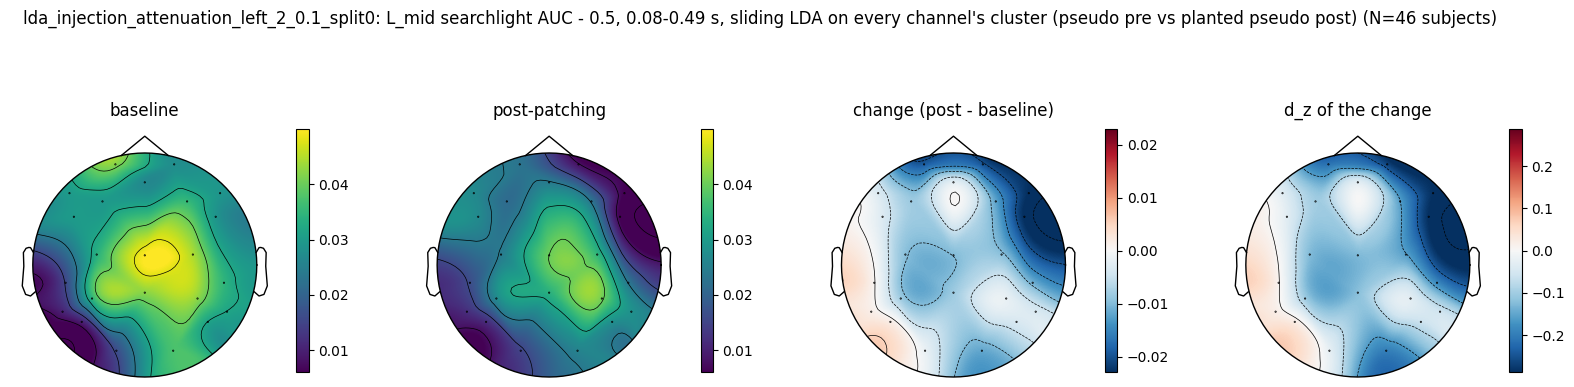

lda_injection_attenuation_left_2_0.1_split0: L_mid searchlight AUC - 0.5, 0.08-0.49 s, change (post - baseline):
  max: A1 +0.0013, T5 +0.0013, T3 +0.0002
  min: F8 -0.0229, T2 -0.0229, FP2 -0.0194
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filt

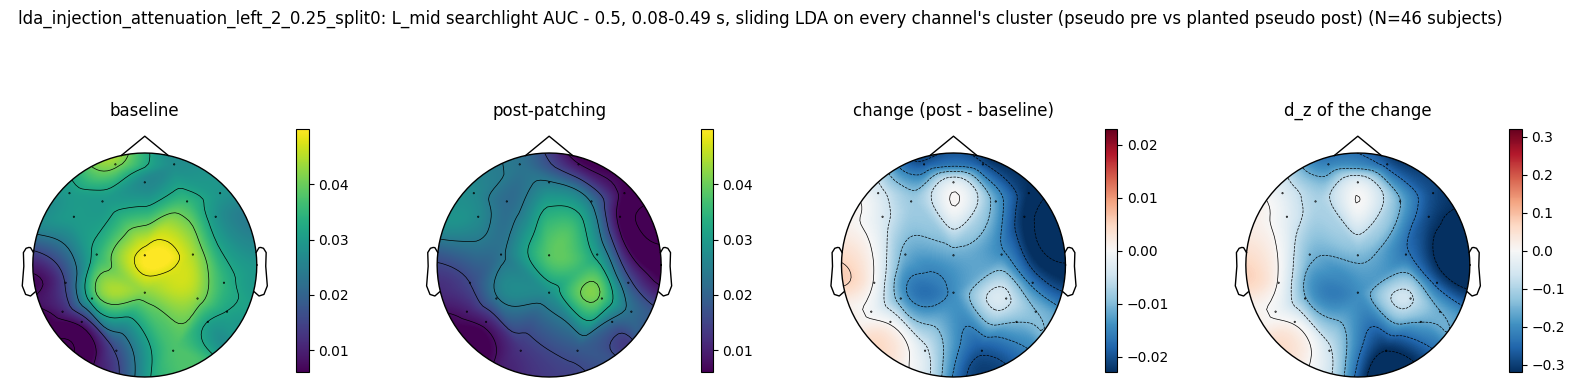

lda_injection_attenuation_left_2_0.25_split0: L_mid searchlight AUC - 0.5, 0.08-0.49 s, change (post - baseline):
  max: T3 -0.0004, T5 -0.0008, A1 -0.0008
  min: F8 -0.0229, T2 -0.0229, FP2 -0.0194
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Fil

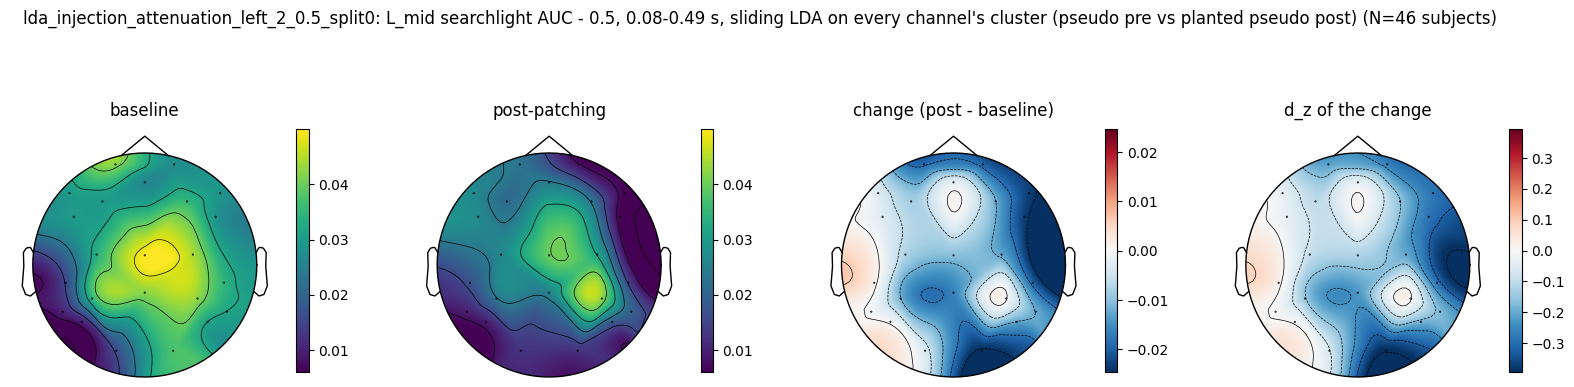

lda_injection_attenuation_left_2_0.5_split0: L_mid searchlight AUC - 0.5, 0.08-0.49 s, change (post - baseline):
  max: T3 +0.0009, P4 +0.0003, A1 -0.0007
  min: O2 -0.0246, F8 -0.0229, T2 -0.0229
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filte

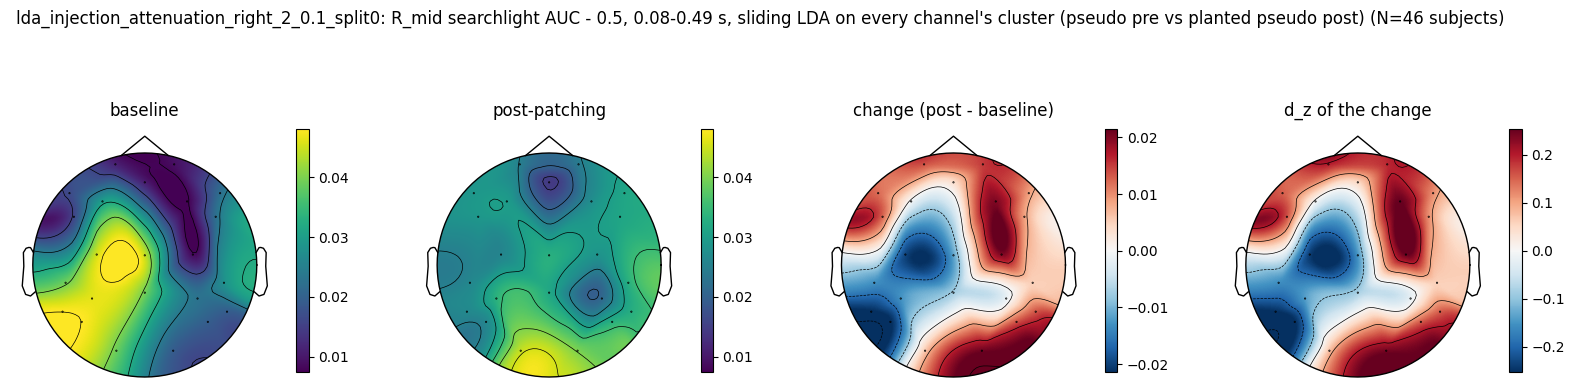

lda_injection_attenuation_right_2_0.1_split0: R_mid searchlight AUC - 0.5, 0.08-0.49 s, change (post - baseline):
  max: O2 +0.0203, F4 +0.0200, C4 +0.0199
  min: A1 -0.0214, T5 -0.0214, C3 -0.0197
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filt

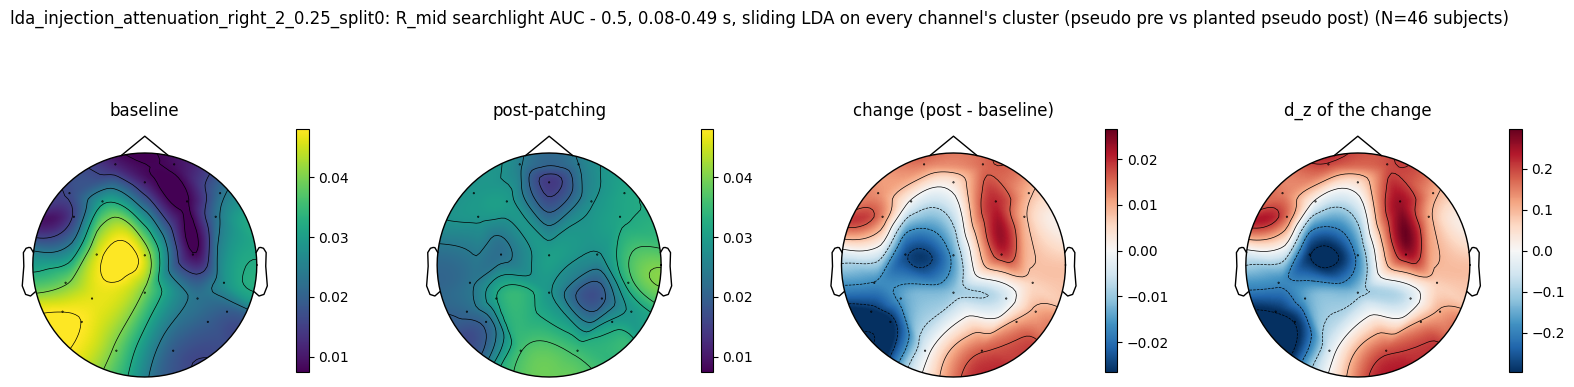

lda_injection_attenuation_right_2_0.25_split0: R_mid searchlight AUC - 0.5, 0.08-0.49 s, change (post - baseline):
  max: F4 +0.0200, C4 +0.0192, O2 +0.0155
  min: A1 -0.0265, T5 -0.0265, C3 -0.0232
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Fil

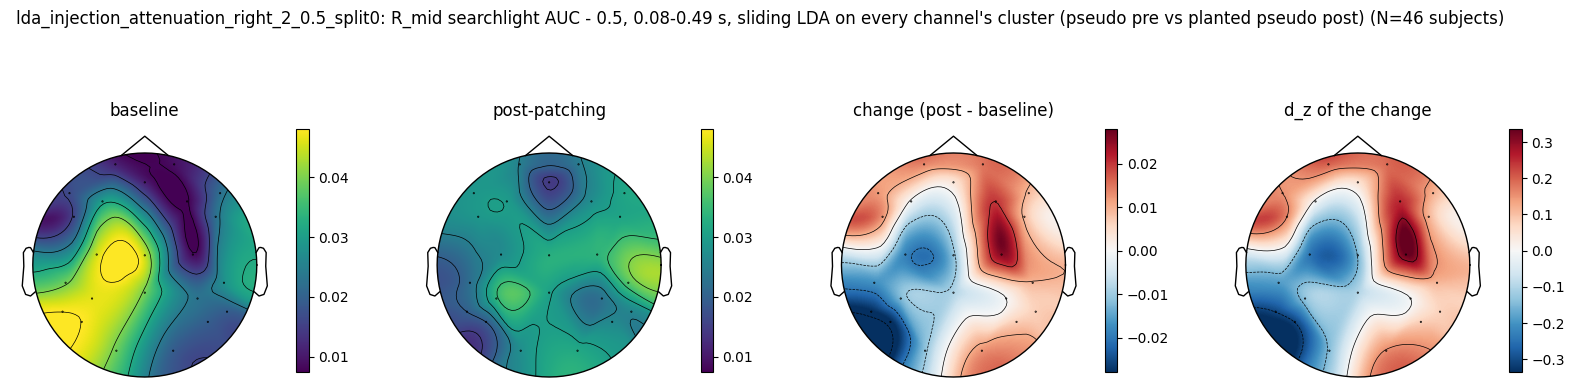

lda_injection_attenuation_right_2_0.5_split0: R_mid searchlight AUC - 0.5, 0.08-0.49 s, change (post - baseline):
  max: C4 +0.0253, F4 +0.0200, FP2 +0.0150
  min: A1 -0.0279, T5 -0.0279, C3 -0.0186


,type,class,size,measure,expected,estimate,se,t,p,n,p_holm
13,attenuation,L_mid,0.10,patched - other accuracy,> 0,0.0239,0.0158,1.5117,0.1378,45.0,1.0000
15,attenuation,L_mid,0.25,patched - other accuracy,> 0,0.0255,0.0156,1.6310,0.1100,45.0,0.8802
17,attenuation,L_mid,0.50,patched - other accuracy,> 0,0.0182,0.0154,1.1819,0.2436,45.0,1.0000
12,attenuation,L_mid,0.10,planted class Δ AUC,< 0,-0.0178,0.0102,-1.7370,0.0892,46.0,NaN
14,attenuation,L_mid,0.25,planted class Δ AUC,< 0,-0.0188,0.0102,-1.8459,0.0715,46.0,NaN
16,attenuation,L_mid,0.50,planted class Δ AUC,< 0,-0.0104,0.0097,-1.0739,0.2886,46.0,NaN
19,attenuation,R_mid,0.10,patched - other accuracy,< 0,0.0160,0.0162,0.9898,0.3277,45.0,1.0000
21,attenuation,R_mid,0.25,patched - other accuracy,< 0,0.0141,0.0165,0.8540,0.3977,45.0,1.0000
23,attenuation,R_mid,0.50,patched - other accuracy,< 0,0.0219,0.0167,1.3085,0.1975,45.0,1.0000
18,attenuation,R_mid,0.10,planted class Δ AUC,< 0,-0.0008,0.0129,-0.0632,0.9499,46.0,NaN


In [20]:
from scipy.stats import ttest_1samp

injection_prefix = "lda_injection"  # --name of decoding/run_lda_injection.py
split_seed = 0  # --split_seed of the delay and attenuation runs analysed
null_split_seeds = [0, 1, 2]  # --split_seed of the null runs analysed (C2 repeats the null with 3 splits)


def injection_test(sliding_name, condition=None, show_maps=True):
    """
    Analyses one run of decoding/run_lda_injection.py (output folder sliding_name) like the real data: the Task B
    contrasts (q4_contrasts, broadband, the fixed accuracy window). With the planted condition also that class's change
    (pseudo post - pseudo pre): of its AUC in the window, per subject (t-test), and of its latency, the fractional peak
    latency of the smoothed mean AUC curves (jackknife, as the Task B latencies); with searchlight outputs and show_maps
    the maps of its searchlight AUC - 0.5 in the window.
    Returns (contrast table, Q4 subjects, {"auc": ..., "latency": ...} of the planted class or None).
    """
    injection_df, injection_sets, _ = load_time_metrics(sliding_name)
    contrasts, subjects_q4 = q4_contrasts(injection_df, accuracy_window, injection_sets[0])
    if condition is None:
        return contrasts, subjects_q4, None

    class_id = settings.CONDITION_CLASS_IDS[condition]
    class_rows = injection_df[(injection_df["metric"] == "auc") & (injection_df["set"] == injection_sets[0])
                              & (injection_df["class"] == class_id)]
    window_rows = class_rows[class_rows["time"].between(accuracy_window[0] - 1e-9, accuracy_window[1] + 1e-9)]
    window_auc = window_rows.groupby(["session", "subject"])["value"].mean().unstack("session").dropna()
    delta = window_auc["postpatch"] - window_auc["baseline"]
    test = ttest_1samp(delta, 0)
    planted = {"auc": {"estimate": delta.mean(), "se": delta.sem(), "t": test.statistic, "p": test.pvalue, "n": len(delta)}}

    curves = class_rows.pivot_table(index=["subject", "session"], columns="time", values="value")
    both = sorted(set(curves.loc[(slice(None), "baseline"), :].index.get_level_values(0))
                  & set(curves.loc[(slice(None), "postpatch"), :].index.get_level_values(0)))
    curve_times = curves.columns.to_numpy()
    smoothing = round(settings.Q4_LATENCY_SMOOTHING / (curve_times[1] - curve_times[0]))
    data = decoding_metrics.smooth(np.stack([[curves.loc[(s, session)].to_numpy() for session in ("baseline", "postpatch")]
                                             for s in both]), smoothing)  # (n_subjects, 2, n_times)
    latency = lambda mean: decoding_metrics.fractional_peak_latency(curve_times, mean, 0.5, settings.Q4_PEAK_FRACTION, settings.Q4_LATENCY_SEARCH)
    planted["latency"] = decoding_metrics.jackknife(lambda m: latency(m[1]) - latency(m[0]), data)

    searchlight_suffix = f"searchlight_{band_file_name(list(settings.DECODING_BANDS)[0])}"
    if show_maps and (settings.INFERENCE_DIR / sliding_name / "1" / f"baseline_{searchlight_suffix}.h5").exists():
        searchlight_df, _, _ = load_time_metrics(sliding_name, file_suffix=searchlight_suffix)
        rows = searchlight_df[(searchlight_df["metric"] == "auc") & (searchlight_df["class"] == class_id)
                              & searchlight_df["time"].between(accuracy_window[0] - 1e-9, accuracy_window[1] + 1e-9)]
        cluster_df = (rows.groupby(["session", "subject", "set"])["value"].mean() - 0.5).rename("searchlight_auc")
        channel_change_topomaps(cluster_df.reset_index().rename(columns={"set": "channel"}),
                                f"{sliding_name}: {settings.LOCATION_CLASSES[condition]['label']} searchlight AUC - 0.5, "
                                f"{accuracy_window[0]}-{accuracy_window[1]} s", value="searchlight_auc",
                                model_label="sliding LDA on every channel's cluster (pseudo pre vs planted pseudo post)")
    return contrasts, subjects_q4, planted


def recovery_rows(plant_type, condition, size, contrasts, subjects_q4, planted):
    """The rows of one planted run for the recovery table: the planted class's change and the side contrast at its eccentricity."""
    info = settings.LOCATION_CLASSES[condition]
    patched = {eyes[s] for s in subjects_q4}
    # +1 if the planted location is on the patched side of every Q4 subject, -1 if on the other side, NaN if mixed or top
    side_sign = (1 if info["side"] in patched else -1) if len(patched) == 1 and info["side"] != "T" else np.nan
    measure = "latency" if plant_type == "delay" else "accuracy"
    expected = size if plant_type == "delay" else -1  # the planted class's change: +d s later, or a drop (sign only)
    side_contrast = contrasts[(contrasts["measure"] == measure) & (contrasts["kind"] == "change")
                              & (contrasts["contrast"] == "patched - other") & (contrasts["ecc"] == info["ecc"])]
    planted_measure = planted["latency" if plant_type == "delay" else "auc"]
    return [{"type": plant_type, "class": info["label"], "size": size, "measure": f"planted class Δ {'latency' if plant_type == 'delay' else 'AUC'}",
             "expected": expected if plant_type == "delay" else "< 0", **{k: planted_measure[k] for k in ("estimate", "se", "t", "p", "n")}},
            {"type": plant_type, "class": info["label"], "size": size, "measure": f"patched - other {measure}",
             "expected": side_sign * expected if plant_type == "delay" else {1: "< 0", -1: "> 0"}.get(side_sign, "?"),
             **side_contrast[["estimate", "se", "t", "p", "p_holm", "n"]].iloc[0].to_dict()}]


# C2: the null runs, nothing planted. C2 concerns the change contrasts; "baseline only" rows test real differences
# between the classes, the same in both halves
for null_seed in null_split_seeds:
    null_contrasts, _, _ = injection_test(f"{injection_prefix}_null_split{null_seed}")
    null_change = null_contrasts[null_contrasts["kind"] == "change"]
    print(f"Null run, split {null_seed}: significant change contrasts after Holm: {int((null_change['p_holm'] < 0.05).sum())} of {len(null_change)}")
    display(null_contrasts.round(4))

# C3 / C4: every delay and attenuation run of the split; recovery table in the handoff's columns (type, class, size,
# estimate, se, t, p), size in s for the delays and as the attenuated fraction for the attenuations ("classattenuation":
# run_lda_injection.py --class_specific, only the location-specific part of the response attenuated)
recovery = []
split_suffix = f"_split{split_seed}"
for plant_type in ("delay", "attenuation", "classattenuation"):
    plant_prefix = f"{injection_prefix}_{plant_type}_"
    for run_dir in sorted(settings.INFERENCE_DIR.glob(f"{plant_prefix}*{split_suffix}")):
        condition, size = run_dir.name[len(plant_prefix):-len(split_suffix)].rsplit("_", 1)
        size = int(size.removesuffix("ms")) / 1000 if plant_type == "delay" else float(size)
        recovery.extend(recovery_rows(plant_type, condition, size, *injection_test(run_dir.name, condition)))
recovery = pd.DataFrame(recovery).sort_values(["type", "class", "measure", "size"])
display(recovery.round(4))


### LaBraM occlusion injection
The masked LaBraM decoder's fold models run once more on their own baseline test trials, with `a` x the subject's
class-average evoked response of the planted condition removed at the posterior channels (0-0.5 s)
(`run_inference.py --class_occlusion_injection`, saved as the post-patching session of `{model}_inj_{a}`). Same model,
same trials: only the planted trials differ, so the maps compare the planted class's trials as recorded ("baseline")
with the same trials injected ("post-patching"). If the occlusion maps localise evidence, the occlusion effect drops at
the posterior clusters and stays at the frontal ones; the relative maps separate this from the overall drop of p_true.

Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

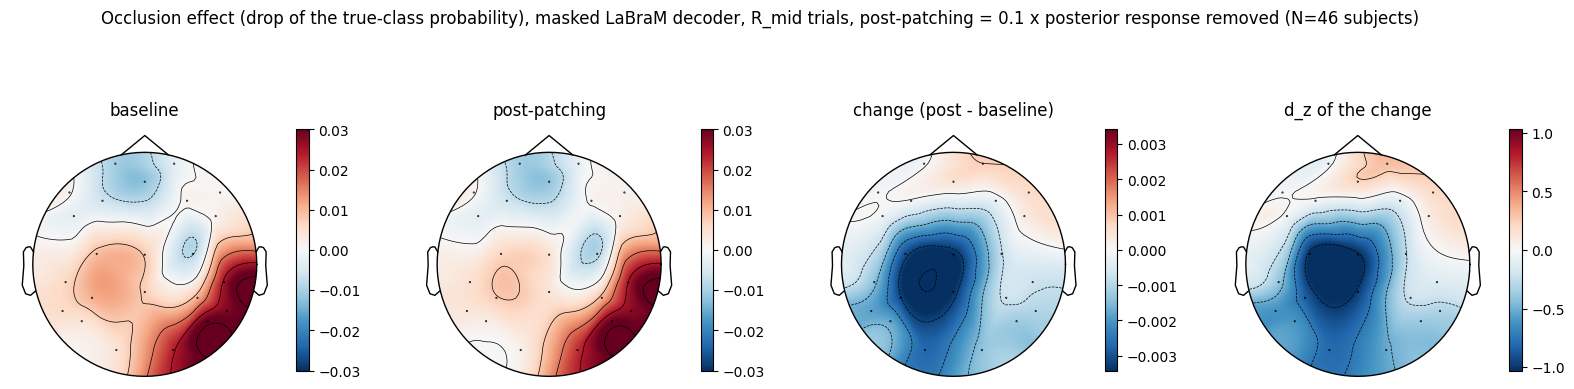

Occlusion effect (drop of the true-class probability), change (post - baseline):
  max: FP2 +0.0008, T2 +0.0006, FZ +0.0005
  min: CZ -0.0034, PZ -0.0034, P3 -0.0032


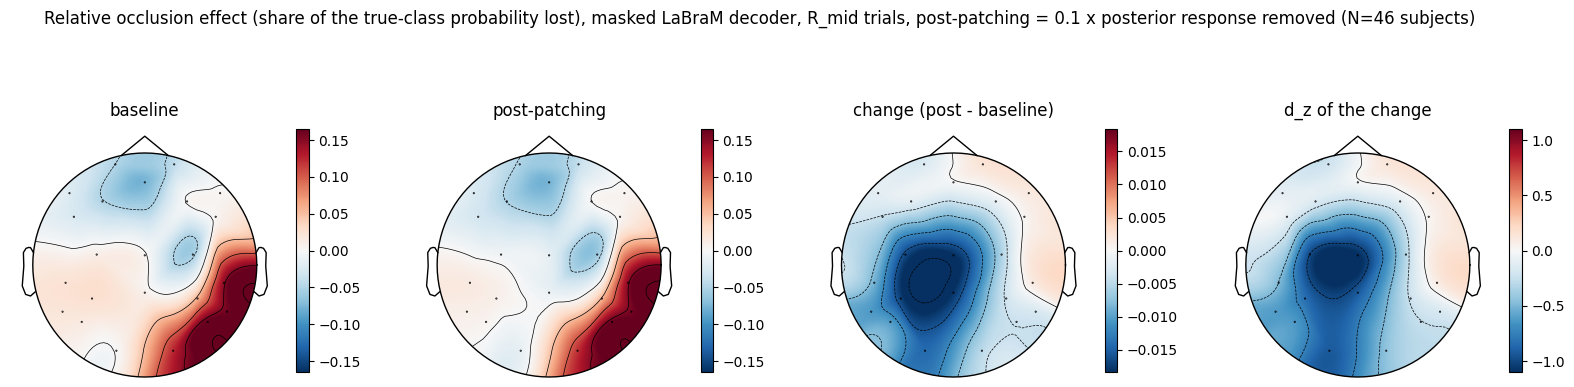

Relative occlusion effect (share of the true-class probability lost), change (post - baseline):
  max: FP2 +0.0024, T2 +0.0017, T4 +0.0015
  min: CZ -0.0183, PZ -0.0180, P3 -0.0174
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
R_mid, attenuation 0.25: p_true 0.1733 -> 0.1631, change -0.0102 (t = -7.85, p = 5.629e-10, N = 46)


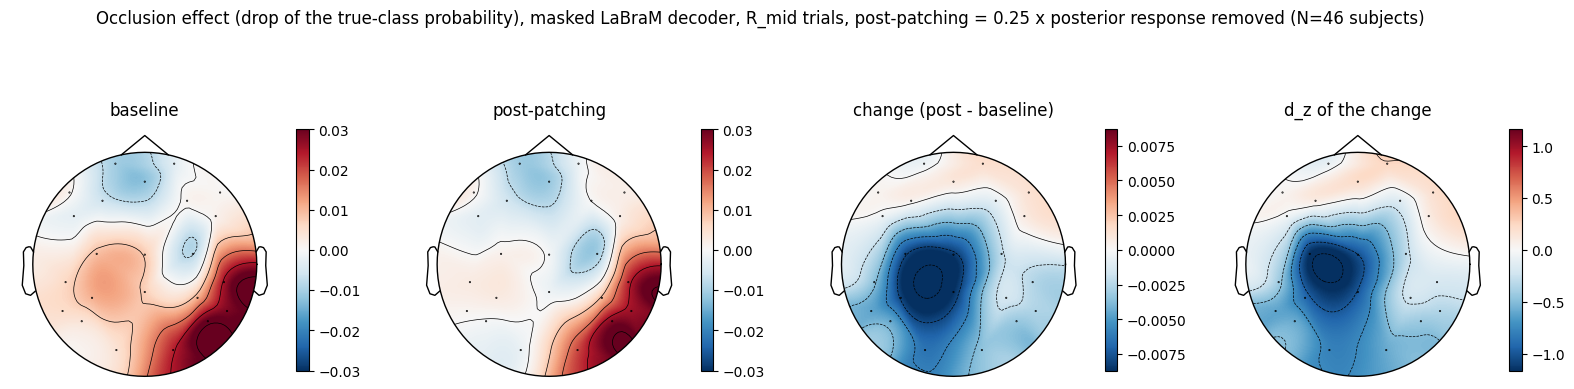

Occlusion effect (drop of the true-class probability), change (post - baseline):
  max: FP2 +0.0014, T2 +0.0013, FZ +0.0009
  min: PZ -0.0087, CZ -0.0083, P3 -0.0082


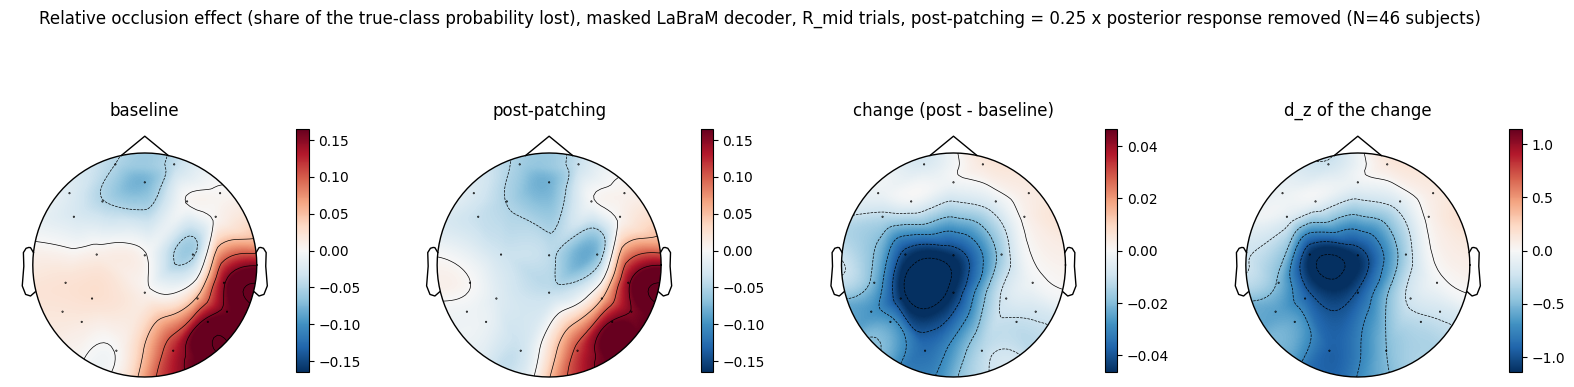

Relative occlusion effect (share of the true-class probability lost), change (post - baseline):
  max: FP2 +0.0045, T2 +0.0035, F8 +0.0014
  min: PZ -0.0463, P3 -0.0458, CZ -0.0449
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
R_mid, attenuation 0.5: p_true 0.1733 -> 0.1538, change -0.0195 (t = -8.12, p = 2.325e-10, N = 46)


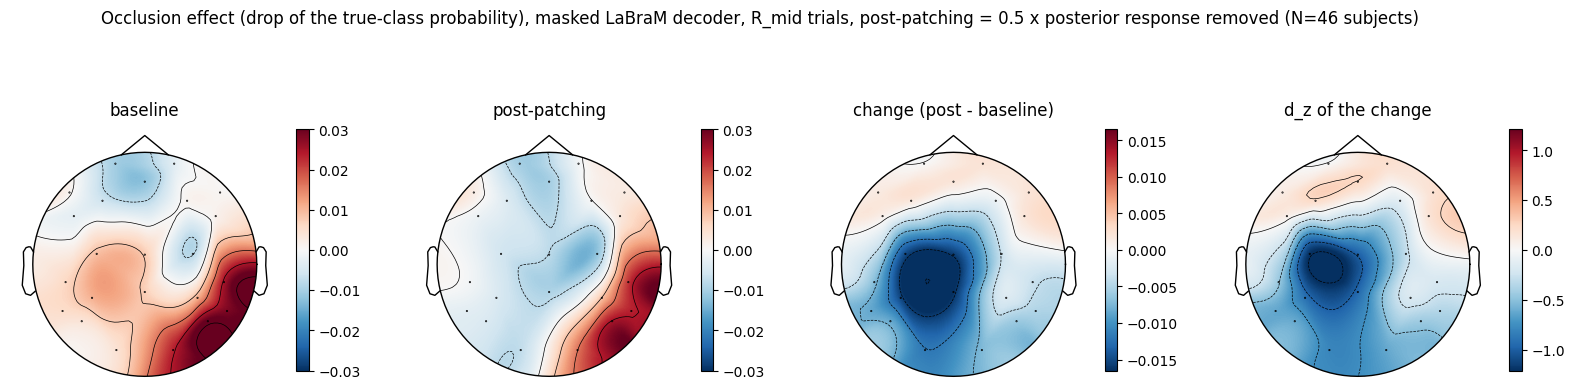

Occlusion effect (drop of the true-class probability), change (post - baseline):
  max: FP2 +0.0022, T2 +0.0021, FZ +0.0020
  min: PZ -0.0166, CZ -0.0156, P3 -0.0154


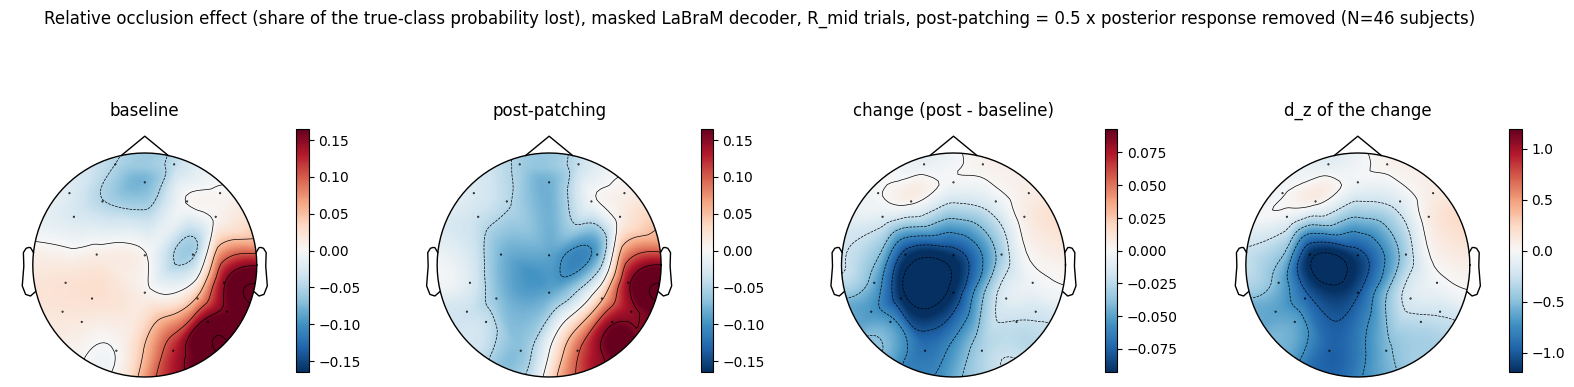

Relative occlusion effect (share of the true-class probability lost), change (post - baseline):
  max: T2 +0.0060, F8 +0.0057, FP2 +0.0033
  min: PZ -0.0927, P3 -0.0923, CZ -0.0890


In [21]:
from scipy.stats import ttest_1samp

labram_injection_model = "class_10_22"  # masked class run trained on the baseline
labram_injection_condition = "right_2"  # --injection_conditions of the injection run
labram_attenuations = [0.1, 0.25, 0.5]  # --class_occlusion_injection values that were run

planted_class = settings.CONDITION_CLASS_IDS[labram_injection_condition]
planted_label = settings.LOCATION_CLASSES[labram_injection_condition]["label"]
regular_df = load_filtered_merged(labram_injection_model, mode="channel", sessions=("baseline",))
regular_df = regular_df[regular_df["label"] == planted_class]
for attenuation in labram_attenuations:
    injected_df = load_filtered_merged(f"{labram_injection_model}_inj_{attenuation:g}", mode="channel", sessions=("postpatch",))
    inj_df = pd.concat([regular_df, injected_df[injected_df["label"] == planted_class]], ignore_index=True)
    inj_df["p_true"] = inj_df["occlusion_effect"] + inj_df["occluded_p_true"]

    # the trial-level true-class probability (the same on every channel row of a trial): it should drop
    subject_p_true = inj_df.groupby(["session", "subject"])["p_true"].mean().unstack("session").dropna()
    drop = subject_p_true["postpatch"] - subject_p_true["baseline"]
    test = ttest_1samp(drop, 0)
    print(f"{planted_label}, attenuation {attenuation:g}: p_true {subject_p_true['baseline'].mean():.4f} -> "
          f"{subject_p_true['postpatch'].mean():.4f}, change {drop.mean():+.4f} (t = {test.statistic:.2f}, p = {test.pvalue:.4g}, N = {len(drop)})")

    model_label = f"masked LaBraM decoder, {planted_label} trials, post-patching = {attenuation:g} x posterior response removed"
    channel_change_topomaps(inj_df, "Occlusion effect (drop of the true-class probability)", model_label=model_label)
    channel_change_topomaps(inj_df, "Relative occlusion effect (share of the true-class probability lost)", relative=True,
                            model_label=model_label)
